# CAREFLOW: Clinical Pathway Process Mining

## 1. Dataset Location Verification

This section checks whether the healthcare dataset is available.

In [1]:
from pathlib import Path

# Find the CareFlow dataset
possible_paths = [
    Path.cwd() / "data" / "raw" / "Sepsis Cases - Event Log.xes.gz",
    Path.cwd().parent / "data" / "raw" / "Sepsis Cases - Event Log.xes.gz",
]

DATA_PATH = next(
    (path.resolve() for path in possible_paths if path.exists()),
    None
)

print("Current working directory:", Path.cwd())
print("Dataset path:", DATA_PATH)
print("Dataset found:", DATA_PATH is not None)

Current working directory: C:\Users\MOHAN\CareFlow
Dataset path: C:\Users\MOHAN\CareFlow\data\raw\Sepsis Cases - Event Log.xes.gz
Dataset found: True


## 2. Loading the Healthcare Event Log

In [2]:
import gzip
import xml.etree.ElementTree as ET
from collections import Counter

# Read the original compressed XES file
with gzip.open(DATA_PATH, "rb") as file:
    root = ET.parse(file).getroot()


def get_tag_name(tag):
    """Remove the XML namespace from a tag."""
    return tag.rsplit("}", 1)[-1]


def get_attributes(element):
    """Extract attributes directly attached to an XML element."""
    attributes = {}

    for child in element:
        key = child.attrib.get("key")

        if key is not None:
            attributes[key] = child.attrib.get("value")

    return attributes


# Find each patient case in the event log
traces = [
    item for item in root
    if get_tag_name(item.tag) == "trace"
]

events = []

# Convert the events into Python dictionaries
for trace in traces:
    case_attributes = get_attributes(trace)
    case_id = case_attributes.get("concept:name")

    for event in trace:
        if get_tag_name(event.tag) != "event":
            continue

        attributes = get_attributes(event)

        row = {
            "case_id": case_id,
            "activity": attributes.get("concept:name"),
            "timestamp": attributes.get("time:timestamp"),
        }

        # Preserve the other event attributes too
        for key, value in attributes.items():
            if key not in ("concept:name", "time:timestamp"):
                row[key] = value

        events.append(row)


# Display summary information
activities = Counter(
    event["activity"] for event in events
)

print("CAREFLOW - DATA LOADED")
print("=" * 35)
print(f"Patient cases: {len(traces):,}")
print(f"Total events: {len(events):,}")
print(f"Distinct activities: {len(activities):,}")

print("\nFirst five events:")
for event in events[:5]:
    print(event)

CAREFLOW - DATA LOADED
Patient cases: 1,050
Total events: 15,214
Distinct activities: 16

First five events:
{'case_id': 'A', 'activity': 'ER Registration', 'timestamp': '2014-10-22T11:15:41.000+02:00', 'InfectionSuspected': 'true', 'org:group': 'A', 'DiagnosticBlood': 'true', 'DisfuncOrg': 'true', 'SIRSCritTachypnea': 'true', 'Hypotensie': 'true', 'SIRSCritHeartRate': 'true', 'Infusion': 'true', 'DiagnosticArtAstrup': 'true', 'Age': '85', 'DiagnosticIC': 'true', 'DiagnosticSputum': 'false', 'DiagnosticLiquor': 'false', 'DiagnosticOther': 'false', 'SIRSCriteria2OrMore': 'true', 'DiagnosticXthorax': 'true', 'SIRSCritTemperature': 'true', 'DiagnosticUrinaryCulture': 'true', 'SIRSCritLeucos': 'false', 'Oligurie': 'false', 'DiagnosticLacticAcid': 'true', 'lifecycle:transition': 'complete', 'Diagnose': 'A', 'Hypoxie': 'false', 'DiagnosticUrinarySediment': 'true', 'DiagnosticECG': 'true'}
{'case_id': 'A', 'activity': 'Leucocytes', 'timestamp': '2014-10-22T11:27:00.000+02:00', 'Leucocytes': '

## pandas installation

In [6]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd

print("Pandas version:", pd.__version__)
print("Pandas is ready for CareFlow!")

Pandas version: 3.0.6
Pandas is ready for CareFlow!


## 3. Converting Events into a Pandas DataFrame

In [8]:
import pandas as pd

# Convert the event records into a DataFrame
df = pd.DataFrame(events)

# Convert timestamps into datetime values
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
    utc=True
)

# Display the dataset structure
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (15214, 32)

Column names:
['case_id', 'activity', 'timestamp', 'InfectionSuspected', 'org:group', 'DiagnosticBlood', 'DisfuncOrg', 'SIRSCritTachypnea', 'Hypotensie', 'SIRSCritHeartRate', 'Infusion', 'DiagnosticArtAstrup', 'Age', 'DiagnosticIC', 'DiagnosticSputum', 'DiagnosticLiquor', 'DiagnosticOther', 'SIRSCriteria2OrMore', 'DiagnosticXthorax', 'SIRSCritTemperature', 'DiagnosticUrinaryCulture', 'SIRSCritLeucos', 'Oligurie', 'DiagnosticLacticAcid', 'lifecycle:transition', 'Diagnose', 'Hypoxie', 'DiagnosticUrinarySediment', 'DiagnosticECG', 'Leucocytes', 'CRP', 'LacticAcid']

First five rows:


,case_id,activity,timestamp,InfectionSuspected,org:group,DiagnosticBlood,DisfuncOrg,SIRSCritTachypnea,Hypotensie,SIRSCritHeartRate,...,Oligurie,DiagnosticLacticAcid,lifecycle:transition,Diagnose,Hypoxie,DiagnosticUrinarySediment,DiagnosticECG,Leucocytes,CRP,LacticAcid
0,A,ER Registration,2014-10-22 09:15:41+00:00,true,A,true,true,true,true,true,...,false,true,complete,A,false,true,true,NaN,NaN,NaN
1,A,Leucocytes,2014-10-22 09:27:00+00:00,NaN,B,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,complete,NaN,NaN,NaN,NaN,9.6,NaN,NaN
2,A,CRP,2014-10-22 09:27:00+00:00,NaN,B,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,complete,NaN,NaN,NaN,NaN,NaN,21.0,NaN
3,A,LacticAcid,2014-10-22 09:27:00+00:00,NaN,B,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,complete,NaN,NaN,NaN,NaN,NaN,NaN,2.2
4,A,ER Triage,2014-10-22 09:33:37+00:00,NaN,C,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,complete,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Missing Values and Duplicate Analysis

In [9]:
# 1. Check the size of the dataset
print("Dataset shape:", df.shape)

# 2. Calculate missing values for every column
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

# Show only columns that contain missing values
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

print("\nColumns with missing values:")
if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary)

# 3. Find exact duplicate event records
duplicate_rows = df[df.duplicated(keep=False)]

print(
    "\nRows belonging to exact duplicate groups:",
    len(duplicate_rows)
)

if not duplicate_rows.empty:
    columns_to_show = [
        "case_id",
        "activity",
        "timestamp",
        "Leucocytes",
        "CRP",
        "org:group",
        "lifecycle:transition"
    ]

    # Display only columns that exist in the dataset
    columns_to_show = [
        col for col in columns_to_show
        if col in df.columns
    ]

    display(
        duplicate_rows[columns_to_show]
        .sort_values(["case_id", "timestamp", "activity"])
    )

Dataset shape: (15214, 32)

Columns with missing values:


,Missing Count,Missing Percentage
Diagnose,14417,94.76
DiagnosticBlood,14164,93.10
InfectionSuspected,14164,93.10
SIRSCritTachypnea,14164,93.10
Hypotensie,14164,93.10
SIRSCritHeartRate,14164,93.10
Infusion,14164,93.10
DiagnosticArtAstrup,14164,93.10
Age,14164,93.10
DiagnosticIC,14164,93.10



Rows belonging to exact duplicate groups: 2


,case_id,activity,timestamp,Leucocytes,CRP,org:group,lifecycle:transition
7160,ES,Leucocytes,2014-11-08 04:50:00+00:00,12.6,NaN,B,complete
7161,ES,Leucocytes,2014-11-08 04:50:00+00:00,12.6,NaN,B,complete


## 5. Attribute Coverage by Clinical Activity

In [10]:
# Attributes we want to investigate
attributes_to_check = [
    "Age",
    "Diagnose",
    "Leucocytes",
    "CRP",
    "LacticAcid"
]

# Keep only attributes that exist in our table
attributes_to_check = [
    col for col in attributes_to_check
    if col in df.columns
]

# Count recorded values for each activity
attribute_coverage = (
    df.groupby("activity")[attributes_to_check]
    .agg(lambda column: column.notna().sum())
)

# Show how many events belong to each activity
attribute_coverage.insert(
    0,
    "Total Events",
    df.groupby("activity").size()
)

display(attribute_coverage)

,Total Events,Age,Diagnose,Leucocytes,CRP,LacticAcid
activity,,,,,,
Admission IC,117,0,0,0,0,0
Admission NC,1182,0,0,0,0,0
CRP,3262,10,5,0,3123,0
ER Registration,1050,995,754,0,0,0
ER Sepsis Triage,1049,7,5,0,0,0
ER Triage,1053,6,4,0,0,0
IV Antibiotics,823,0,0,0,0,0
IV Liquid,753,14,13,0,0,0
LacticAcid,1466,0,0,0,0,1454


## 6. Missing Values in Relevant Activities

In [11]:
# Check completeness within relevant activities
checks = {
    "CRP": ("CRP", "CRP"),
    "Leucocytes": ("Leucocytes", "Leucocytes"),
    "LacticAcid": ("LacticAcid", "LacticAcid"),
    "Age at ER Registration": ("ER Registration", "Age"),
}

results = []

for label, (activity_name, attribute) in checks.items():
    subset = df[df["activity"] == activity_name]

    total = len(subset)
    present = subset[attribute].notna().sum()
    missing = total - present

    results.append({
        "Check": label,
        "Total Events": total,
        "Values Present": present,
        "Values Missing": missing,
        "Missing Percentage": (
            round(missing / total * 100, 2)
            if total else None
        )
    })

completeness = pd.DataFrame(results).set_index("Check")

display(completeness)

,Total Events,Values Present,Values Missing,Missing Percentage
Check,,,,
CRP,3262,3123,139,4.26
Leucocytes,3383,3361,22,0.65
LacticAcid,1466,1454,12,0.82
Age at ER Registration,1050,995,55,5.24


## 7. Preparing the Analysis-Ready Event Log

In [12]:
from pathlib import Path

# Create a separate working copy.
analysis_df = df.copy()

# Assign a unique technical ID to each event row.
analysis_df.insert(
    0,
    "event_id",
    range(1, len(analysis_df) + 1)
)

# Flag every row belonging to an exact duplicate group.
original_columns = df.columns.tolist()

analysis_df["is_exact_duplicate_candidate"] = (
    analysis_df.duplicated(
        subset=original_columns,
        keep=False
    )
)

# Prepare the output location.
output_path = (
    Path.cwd()
    / "data"
    / "processed"
    / "careflow_event_log.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Save the prepared copy without changing the original.
analysis_df.to_csv(output_path, index=False)

# Verify the output.
print("CAREFLOW - PREPARED EVENT LOG")
print("=" * 40)
print("Original events:", len(df))
print("Prepared events:", len(analysis_df))
print("Total columns:", len(analysis_df.columns))
print(
    "Duplicate-candidate rows:",
    int(analysis_df["is_exact_duplicate_candidate"].sum())
)
print("Missing case IDs:", analysis_df["case_id"].isna().sum())
print("Missing activity names:", analysis_df["activity"].isna().sum())
print("Missing timestamps:", analysis_df["timestamp"].isna().sum())
print("Saved to:", output_path)

display(
    analysis_df.loc[
        analysis_df["is_exact_duplicate_candidate"],
        [
            "event_id",
            "case_id",
            "activity",
            "timestamp",
            "is_exact_duplicate_candidate"
        ]
    ]
)

CAREFLOW - PREPARED EVENT LOG
Original events: 15214
Prepared events: 15214
Total columns: 34
Duplicate-candidate rows: 2
Missing case IDs: 0
Missing activity names: 0
Missing timestamps: 0
Saved to: C:\Users\MOHAN\CareFlow\data\processed\careflow_event_log.csv


,event_id,case_id,activity,timestamp,is_exact_duplicate_candidate
7160,7161,ES,Leucocytes,2014-11-08 04:50:00+00:00,True
7161,7162,ES,Leucocytes,2014-11-08 04:50:00+00:00,True


## 8. Patient Journey Analysis

In [13]:
# Sort events within each patient case by timestamp.
# event_id preserves the original ordering when timestamps tie.
ordered = analysis_df.sort_values(
    ["case_id", "timestamp", "event_id"]
).copy()

# Summarize each patient's journey.
case_summary = (
    ordered.groupby("case_id", as_index=False)
    .agg(
        total_events=("activity", "size"),
        distinct_activities=("activity", "nunique"),
        first_event=("timestamp", "min"),
        last_event=("timestamp", "max"),
    )
)

# Calculate the span between the first and last recorded events.
case_summary["duration_hours"] = (
    case_summary["last_event"] - case_summary["first_event"]
).dt.total_seconds() / 3600

print("PATIENT JOURNEY SUMMARY")
print("=" * 40)
print("Patient cases:", len(case_summary))

print("\nEvents per patient:")
display(
    case_summary["total_events"]
    .describe()
    .round(2)
    .to_frame("Events per patient")
)

print("\nRecorded pathway span in hours:")
display(
    case_summary["duration_hours"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .round(2)
    .to_frame("Duration (hours)")
)

print("\nFirst five patient summaries:")
display(case_summary.head())

PATIENT JOURNEY SUMMARY
Patient cases: 1050

Events per patient:


,Events per patient
count,1050.00
mean,14.49
std,11.48
min,3.00
25%,9.00
50%,13.00
75%,16.00
max,185.00



Recorded pathway span in hours:


,Duration (hours)
count,1050.00
mean,683.26
std,1452.89
min,0.03
25%,15.44
50%,128.24
75%,431.92
max,10135.77



First five patient summaries:


,case_id,total_events,distinct_activities,first_event,last_event,duration_hours
0,A,22,10,2014-10-22 09:15:41+00:00,2014-11-02 14:15:00+00:00,268.988611
1,AA,8,8,2014-12-03 08:06:44+00:00,2014-12-03 13:28:01+00:00,5.354722
2,AAA,11,11,2014-11-19 02:16:21+00:00,2014-11-28 15:15:17+00:00,228.982222
3,AB,8,8,2014-02-16 08:55:43+00:00,2014-02-16 12:52:06+00:00,3.939722
4,ABA,17,10,2014-10-12 09:22:24+00:00,2014-10-18 14:15:00+00:00,148.876667


## 9. Most Common Clinical Pathways

In [14]:
# Represent each patient journey as an ordered sequence of activities.
pathways = (
    ordered.groupby("case_id")["activity"]
    .agg(tuple)
)

# Count how many cases follow each exact sequence.
pathway_counts = (
    pathways.value_counts()
    .rename_axis("activities")
    .reset_index(name="case_count")
)

# Convert activity sequences into readable pathway text.
pathway_counts["pathway"] = pathway_counts["activities"].apply(
    lambda activities: " → ".join(map(str, activities))
)

print("TOP 10 MOST COMMON CLINICAL PATHWAYS")
print("=" * 40)

display(
    pathway_counts[
        ["case_count", "pathway"]
    ].head(10)
)

TOP 10 MOST COMMON CLINICAL PATHWAYS


,case_count,pathway
0,35,ER Registration → ER Triage → ER Sepsis Triage
1,24,ER Registration → ER Triage → ER Sepsis Triage...
2,22,ER Registration → ER Triage → ER Sepsis Triage...
3,13,ER Registration → ER Triage → ER Sepsis Triage...
4,11,ER Registration → ER Triage → ER Sepsis Triage...
5,9,ER Registration → ER Triage → ER Sepsis Triage...
6,7,ER Registration → ER Triage → ER Sepsis Triage...
7,5,ER Registration → ER Triage → ER Sepsis Triage...
8,5,ER Registration → ER Triage → CRP → Leucocytes...
9,5,ER Registration → ER Triage → ER Sepsis Triage...


## 10. Activity Transition and Duration Analysis

In [15]:
# Sort events chronologically within each patient case.
ordered = analysis_df.sort_values(
    ["case_id", "timestamp", "event_id"]
).copy()

# Find the next event in the same patient case.
ordered["next_activity"] = (
    ordered.groupby("case_id")["activity"].shift(-1)
)

ordered["next_timestamp"] = (
    ordered.groupby("case_id")["timestamp"].shift(-1)
)

# Keep rows that have a next activity.
transitions = ordered[
    ordered["next_activity"].notna()
].copy()

# Calculate elapsed time between consecutive events.
transitions["elapsed_hours"] = (
    transitions["next_timestamp"] - transitions["timestamp"]
).dt.total_seconds() / 3600

# Create a readable activity-pair label.
transitions["transition"] = (
    transitions["activity"]
    + " → "
    + transitions["next_activity"]
)

print("TRANSITION ANALYSIS")
print("=" * 45)
print("Patient cases:", analysis_df["case_id"].nunique())
print("Recorded events:", len(ordered))
print("Consecutive-event transitions:", len(transitions))
print(
    "Negative elapsed intervals:",
    int((transitions["elapsed_hours"] < 0).sum())
)

print("\nElapsed time between consecutive events (hours):")
display(
    transitions["elapsed_hours"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .round(2)
    .to_frame("Elapsed hours")
)

# Summarize each type of activity transition.
transition_summary = (
    transitions.groupby(
        ["activity", "next_activity"],
        as_index=False
    )
    .agg(
        transition_count=("case_id", "size"),
        patient_cases=("case_id", "nunique"),
        median_hours=("elapsed_hours", "median"),
        mean_hours=("elapsed_hours", "mean"),
        p90_hours=(
            "elapsed_hours",
            lambda values: values.quantile(0.90)
        )
    )
)

transition_summary["transition"] = (
    transition_summary["activity"]
    + " → "
    + transition_summary["next_activity"]
)

# Show transitions with the most recorded occurrences.
print("\nTOP 10 MOST FREQUENT TRANSITIONS")

display(
    transition_summary.sort_values(
        "transition_count",
        ascending=False
    )[
        [
            "transition",
            "transition_count",
            "patient_cases",
            "median_hours",
            "p90_hours"
        ]
    ].head(10).round(2)
)

# Restrict the long-interval ranking to transitions
# observed at least 10 times for a more useful comparison.
repeated_transitions = transition_summary[
    transition_summary["transition_count"] >= 10
]

print("\n10 LONGEST-MEDIAN TRANSITIONS")
print("(Restricted to transitions observed at least 10 times)")

display(
    repeated_transitions.sort_values(
        "median_hours",
        ascending=False
    )[
        [
            "transition",
            "transition_count",
            "patient_cases",
            "median_hours",
            "mean_hours",
            "p90_hours"
        ]
    ].head(10).round(2)
)

TRANSITION ANALYSIS
Patient cases: 1050
Recorded events: 15214
Consecutive-event transitions: 14164
Negative elapsed intervals: 0

Elapsed time between consecutive events (hours):


,Elapsed hours
count,14164.00
mean,50.65
std,415.19
min,0.00
25%,0.00
50%,0.11
75%,7.25
90%,48.00
max,10014.25



TOP 10 MOST FREQUENT TRANSITIONS


,transition,transition_count,patient_cases,median_hours,p90_hours
93,Leucocytes → CRP,1778,758,0.00,24.00
28,CRP → Leucocytes,1445,647,0.00,48.00
37,ER Registration → ER Triage,971,971,0.13,0.37
52,ER Triage → ER Sepsis Triage,905,905,0.01,0.07
27,CRP → LacticAcid,629,417,0.00,0.00
87,LacticAcid → Leucocytes,565,366,0.00,10.72
73,IV Liquid → IV Antibiotics,501,501,0.00,0.58
58,IV Antibiotics → Admission NC,489,489,0.10,3.02
100,Leucocytes → Leucocytes,458,217,24.00,72.00
99,Leucocytes → LacticAcid,435,312,0.00,2.62



10 LONGEST-MEDIAN TRANSITIONS
(Restricted to transitions observed at least 10 times)


,transition,transition_count,patient_cases,median_hours,mean_hours,p90_hours
109,Release A → Return ER,276,276,1134.40,1976.14,5120.61
112,Release D → Return ER,10,10,506.90,1334.48,4027.35
31,CRP → Release C,13,13,97.50,110.05,145.80
15,Admission NC → Release A,117,117,67.74,77.80,123.60
32,CRP → Release D,12,12,62.12,84.81,170.32
104,Leucocytes → Release D,11,11,52.98,85.79,167.50
21,CRP → CRP,317,210,48.00,47.68,87.00
29,CRP → Release A,322,322,31.25,46.92,98.73
101,Leucocytes → Release A,225,225,30.25,46.99,99.97
102,Leucocytes → Release B,14,14,28.51,49.63,111.00


## 11. Investigation of Long Recorded Intervals

In [16]:
# Display the 10 longest intervals between consecutive events
longest_intervals = transitions.sort_values(
    "elapsed_hours",
    ascending=False
).head(10)

columns_to_show = [
    "case_id",
    "activity",
    "timestamp",
    "next_activity",
    "next_timestamp",
    "elapsed_hours"
]

print("CAREFLOW - LONGEST RECORDED INTERVALS")
print("=" * 50)

display(
    longest_intervals[columns_to_show].round(
        {"elapsed_hours": 2}
    )
)

# Examine Release A -> Return ER transitions separately
release_return = transitions[
    (transitions["activity"] == "Release A")
    & (transitions["next_activity"] == "Return ER")
].copy()

print("\nRELEASE A -> RETURN ER")
print("=" * 50)
print("Number of transitions:", len(release_return))
print(
    "Median interval (hours):",
    round(release_return["elapsed_hours"].median(), 2)
)
print(
    "Minimum interval (hours):",
    round(release_return["elapsed_hours"].min(), 2)
)
print(
    "Maximum interval (hours):",
    round(release_return["elapsed_hours"].max(), 2)
)

display(
    release_return[
        [
            "case_id",
            "timestamp",
            "next_timestamp",
            "elapsed_hours"
        ]
    ].head(10)
)

CAREFLOW - LONGEST RECORDED INTERVALS


,case_id,activity,timestamp,next_activity,next_timestamp,elapsed_hours
2523,HG,Release A,2013-12-18 12:30:00+00:00,Return ER,2015-02-08 18:45:18+00:00,10014.25
10539,VAA,Release A,2014-02-12 10:55:37+00:00,Return ER,2015-04-03 08:55:52+00:00,9958.00
7554,ZS,Release A,2013-11-16 09:00:00+00:00,Return ER,2014-12-18 09:08:54+00:00,9528.15
7361,LS,Release A,2013-11-21 11:00:00+00:00,Return ER,2014-12-20 15:39:26+00:00,9460.66
10886,UBA,Release A,2014-05-23 09:00:00+00:00,Return ER,2015-05-30 09:14:55+00:00,8928.25
3113,AI,Release A,2013-12-24 13:00:00+00:00,Return ER,2014-12-19 01:38:36+00:00,8628.64
11408,HDA,Release A,2014-01-12 15:30:00+00:00,Return ER,2015-01-04 18:28:24+00:00,8570.97
5453,LN,Release A,2014-02-24 16:00:00+00:00,Return ER,2015-01-27 12:12:50+00:00,8084.21
1832,KE,Release A,2013-12-21 11:00:00+00:00,Return ER,2014-11-17 14:54:09+00:00,7947.90
4366,AL,Release A,2014-04-14 13:00:00+00:00,Return ER,2015-02-22 05:16:14+00:00,7528.27



RELEASE A -> RETURN ER
Number of transitions: 276
Median interval (hours): 1134.4
Minimum interval (hours): 7.0
Maximum interval (hours): 10014.25


,case_id,timestamp,next_timestamp,elapsed_hours
10242,AAA,2014-11-22 10:30:00+00:00,2014-11-28 15:15:17+00:00,148.754722
890,AC,2014-09-30 09:30:00+00:00,2014-12-02 17:47:17+00:00,1520.288056
1245,AD,2014-01-04 10:45:00+00:00,2014-05-04 16:34:00+00:00,2885.816667
11322,ADA,2014-07-06 08:00:00+00:00,2014-07-06 18:42:00+00:00,10.700000
1706,AE,2014-03-18 11:00:00+00:00,2014-07-23 15:38:24+00:00,3052.640000
2028,AF,2014-04-12 09:00:00+00:00,2014-04-20 00:58:15+00:00,183.970833
12035,AFA,2014-04-25 09:20:00+00:00,2014-07-13 11:18:24+00:00,1897.973333
3113,AI,2013-12-24 13:00:00+00:00,2014-12-19 01:38:36+00:00,8628.643333
13222,AIA,2014-05-29 12:00:00+00:00,2014-06-09 14:49:06+00:00,266.818333
4366,AL,2014-04-14 13:00:00+00:00,2015-02-22 05:16:14+00:00,7528.270556


## Installing libraries

In [19]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 12. Clinical Activity Frequency Visualization

Matplotlib is building the font cache; this may take a moment.


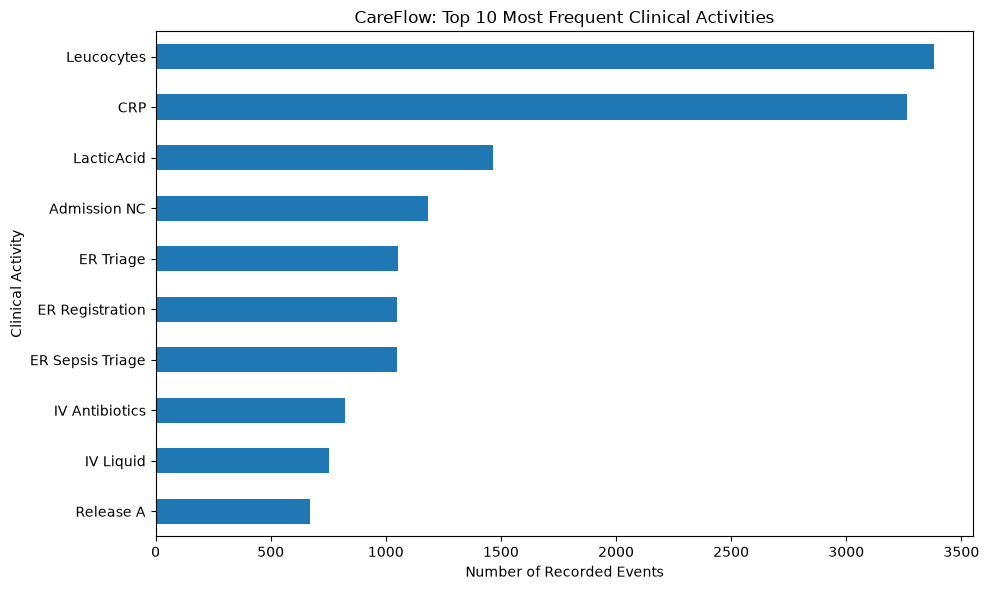

In [20]:
import matplotlib.pyplot as plt

# Count how often each activity occurs
activity_counts = (
    df["activity"]
    .value_counts()
    .head(10)
    .sort_values()
)

# Draw a horizontal bar chart
plt.figure(figsize=(10, 6))

activity_counts.plot(kind="barh")

plt.title("CareFlow: Top 10 Most Frequent Clinical Activities")
plt.xlabel("Number of Recorded Events")
plt.ylabel("Clinical Activity")
plt.tight_layout()
plt.show()

## 13. Clinical Activity Transition Visualization

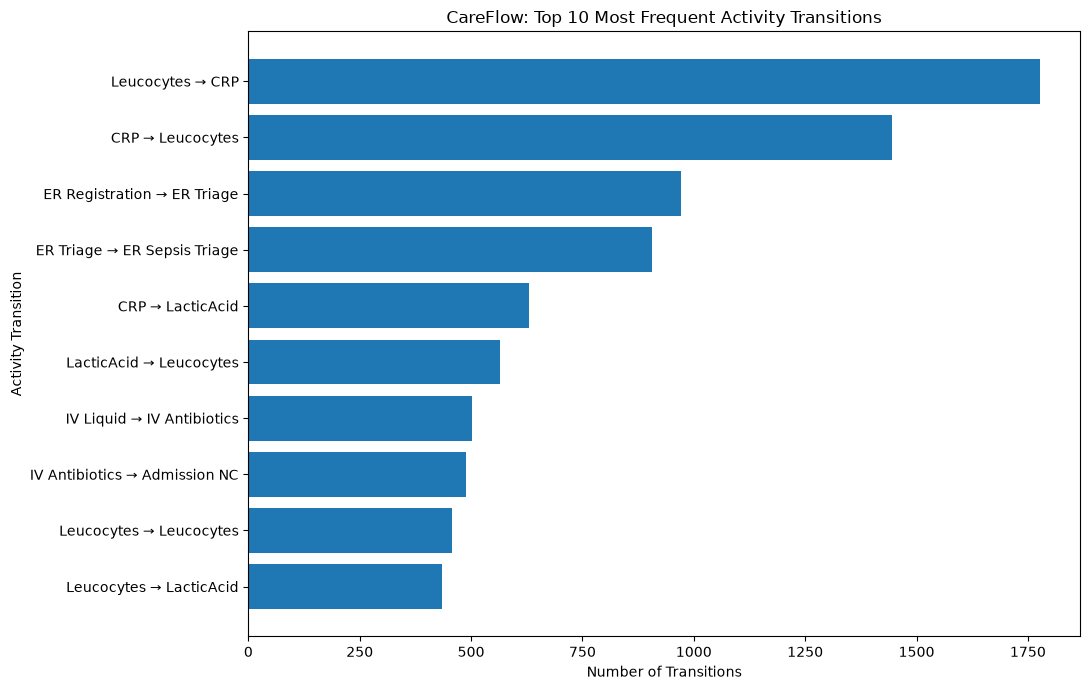

In [21]:
top_transitions = (
    transition_summary
    .nlargest(10, "transition_count")
    .sort_values("transition_count")
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_transitions["transition"],
    top_transitions["transition_count"]
)

plt.title("CareFlow: Top 10 Most Frequent Activity Transitions")
plt.xlabel("Number of Transitions")
plt.ylabel("Activity Transition")
plt.tight_layout()
plt.show()

## 14. Process Discovery Using PM4Py

In [29]:
%pip install pm4py

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import pm4py

print("PM4Py version:", pm4py.__version__)
print("Process mining library is ready!")



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




PM4Py version: 2.7.23.11
Process mining library is ready!


## 15. Directly-Follows Process Map

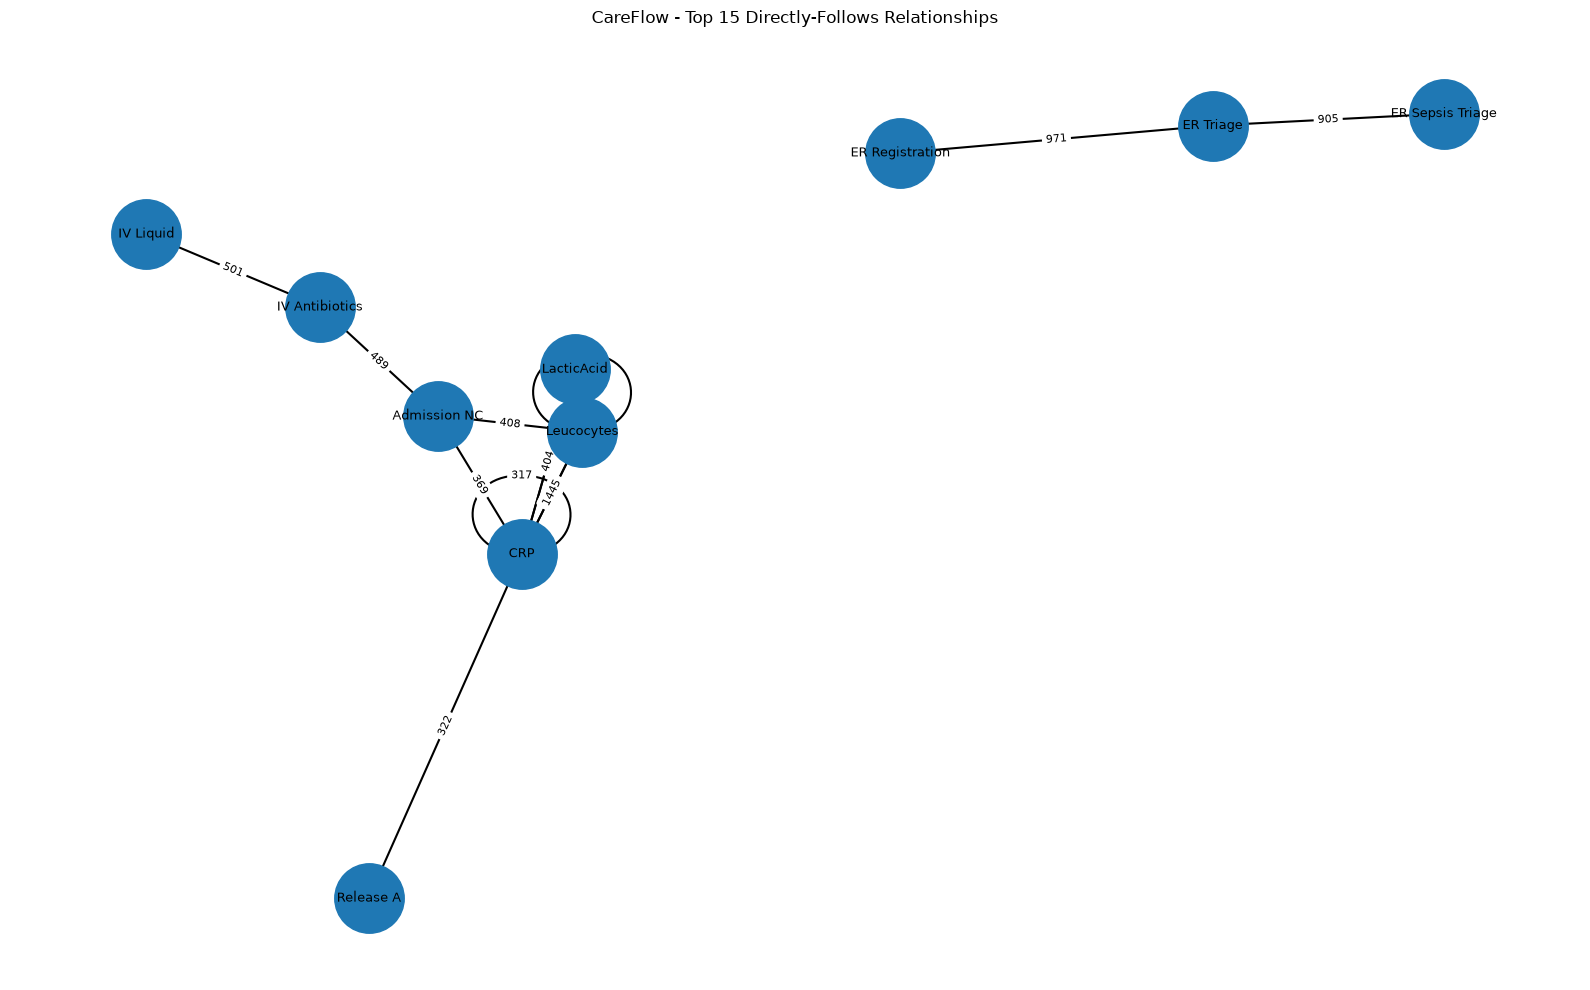

In [31]:
import matplotlib.pyplot as plt
import networkx as nx

# Select the strongest process relationships
top_dfg = dfg_table.head(15)

# Create a directed graph
G = nx.DiGraph()

for _, row in top_dfg.iterrows():
    G.add_edge(
        row["From Activity"],
        row["To Activity"],
        weight=row["Count"]
    )

# Create a readable layout
plt.figure(figsize=(16, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=2.5
)

# Draw nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2500
)

# Draw edges
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=18,
    width=1.5
)

# Draw activity names
nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

# Draw transition counts
edge_labels = {
    (u, v): data["weight"]
    for u, v, data in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    "CareFlow - Top 15 Directly-Follows Relationships"
)

plt.axis("off")
plt.tight_layout()
plt.show()

## 16. Process Variants Analysis

In [33]:
variant_table = pd.DataFrame({
    "Process Variant": variant_counts.index,
    "Case Count": variant_counts.values
})

variant_table["Percentage"] = (
    variant_table["Case Count"] / len(process_variants) * 100
)

variant_table = variant_table.reset_index(drop=True)

variant_table.head(15)

,Process Variant,Case Count,Percentage
0,ER Registration → ER Triage → ER Sepsis Triage,35,3.333333
1,ER Registration → ER Triage → ER Sepsis Triage...,24,2.285714
2,ER Registration → ER Triage → ER Sepsis Triage...,22,2.095238
3,ER Registration → ER Triage → ER Sepsis Triage...,13,1.238095
4,ER Registration → ER Triage → ER Sepsis Triage...,11,1.047619
5,ER Registration → ER Triage → ER Sepsis Triage...,9,0.857143
6,ER Registration → ER Triage → ER Sepsis Triage...,7,0.666667
7,ER Registration → ER Triage → ER Sepsis Triage...,5,0.476190
8,ER Registration → ER Triage → CRP → Leucocytes...,5,0.476190
9,ER Registration → ER Triage → ER Sepsis Triage...,5,0.476190


## 17. Rare and Unusual Process Variants

In [34]:
# Identify rare process variants
rare_variants = variant_table[
    variant_table["Case Count"] <= 2
].copy()

print("Total unique process variants:", len(variant_table))
print("Rare variants (2 or fewer cases):", len(rare_variants))

rare_variants.head(20)

Total unique process variants: 846
Rare variants (2 or fewer cases): 819


,Process Variant,Case Count,Percentage
27,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
28,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
29,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
30,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
31,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
32,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
33,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
34,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
35,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476
36,ER Registration → ER Triage → ER Sepsis Triage...,2,0.190476


## 18. Pathway Complexity Analysis

In [35]:
# Calculate the number of activities in each process variant
variant_table["Number of Activities"] = (
    variant_table["Process Variant"]
    .str.split(" → ")
    .str.len()
)

# Sort by pathway complexity
complex_variants = variant_table.sort_values(
    "Number of Activities",
    ascending=False
)

# Display the 15 most complex pathways
complex_variants.head(15)

,Process Variant,Case Count,Percentage,Number of Activities
472,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,185
392,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,170
498,ER Registration → CRP → Leucocytes → ER Triage...,1,0.095238,118
261,Leucocytes → CRP → ER Registration → ER Triage...,1,0.095238,88
813,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,84
837,IV Liquid → ER Registration → ER Triage → ER S...,1,0.095238,66
803,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,61
491,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,61
255,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,59
449,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,52


In [36]:
complex_variants = (
    variant_table
    .sort_values("Number of Activities", ascending=False)
    .reset_index(drop=True)
)

complex_variants.head(15)

,Process Variant,Case Count,Percentage,Number of Activities
0,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,185
1,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,170
2,ER Registration → CRP → Leucocytes → ER Triage...,1,0.095238,118
3,Leucocytes → CRP → ER Registration → ER Triage...,1,0.095238,88
4,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,84
5,IV Liquid → ER Registration → ER Triage → ER S...,1,0.095238,66
6,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,61
7,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,61
8,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,59
9,ER Registration → ER Triage → ER Sepsis Triage...,1,0.095238,52


## 19. Clinical Activity Repetition Analysis

In [37]:
# Count how many times each activity occurs within each patient case
activity_repetition = (
    analysis_df
    .groupby(["case_id", "activity"])
    .size()
    .reset_index(name="Occurrence Count")
)

# Keep only repeated activities
repeated_activities = activity_repetition[
    activity_repetition["Occurrence Count"] > 1
].copy()

# Sort by highest repetition
repeated_activities = repeated_activities.sort_values(
    "Occurrence Count",
    ascending=False
)

print("Patient-activity combinations with repeated activities:",
      len(repeated_activities))

repeated_activities.head(20)

Patient-activity combinations with repeated activities: 1864


,case_id,activity,Occurrence Count
5000,NGA,Leucocytes,74
4993,NGA,CRP,69
4004,KM,Leucocytes,57
3997,KM,CRP,51
4003,KM,LacticAcid,51
2465,GK,Leucocytes,46
5310,OD,Leucocytes,38
5309,OD,LacticAcid,37
5303,OD,CRP,36
4999,NGA,LacticAcid,31


## 20. Most Frequently Repeated Clinical Activities

In [38]:
# Count repeated occurrences across all patient journeys
repeated_activity_summary = (
    repeated_activities
    .groupby("activity")
    .agg(
        Patient_Count=("case_id", "nunique"),
        Total_Repeated_Occurrences=("Occurrence Count", "sum"),
        Maximum_Occurrences=("Occurrence Count", "max")
    )
    .sort_values(
        "Total_Repeated_Occurrences",
        ascending=False
    )
)

repeated_activity_summary

,Patient_Count,Total_Repeated_Occurrences,Maximum_Occurrences
activity,,,
Leucocytes,677,3048,74
CRP,692,2947,69
LacticAcid,172,778,51
Admission NC,313,695,5
Admission IC,7,14,2
ER Triage,3,6,2


## 21. High-Repetition Patient Analysis

In [39]:
# Calculate total recorded activities for each patient
patient_activity_summary = (
    analysis_df
    .groupby("case_id")
    .agg(
        Total_Activities=("activity", "size"),
        Unique_Activities=("activity", "nunique")
    )
)

# Calculate number of repeated activities
patient_activity_summary["Repeated_Activities"] = (
    patient_activity_summary["Total_Activities"]
    - patient_activity_summary["Unique_Activities"]
)

# Sort by highest repetition
high_repetition_patients = (
    patient_activity_summary
    .sort_values("Repeated_Activities", ascending=False)
)

high_repetition_patients.head(15)

,Total_Activities,Unique_Activities,Repeated_Activities
case_id,,,
NGA,185,11,174
KM,170,12,158
OD,118,10,108
GK,88,11,77
YX,84,11,73
ZMA,66,11,55
YLA,61,10,51
NZ,61,12,49
GF,59,12,47


## 22. Patient-Level Outlier Analysis

In [40]:
# Calculate average and standard deviation of total activities
mean_activities = patient_activity_summary["Total_Activities"].mean()
std_activities = patient_activity_summary["Total_Activities"].std()

# Define high-activity outliers
outlier_threshold = mean_activities + 2 * std_activities

activity_outliers = patient_activity_summary[
    patient_activity_summary["Total_Activities"] > outlier_threshold
].copy()

print("Average activities per patient:", round(mean_activities, 2))
print("Standard deviation:", round(std_activities, 2))
print("Outlier threshold:", round(outlier_threshold, 2))
print("Number of high-activity outlier patients:", len(activity_outliers))

activity_outliers.sort_values(
    "Total_Activities",
    ascending=False
)

Average activities per patient: 14.49
Standard deviation: 11.48
Outlier threshold: 37.44
Number of high-activity outlier patients: 23


,Total_Activities,Unique_Activities,Repeated_Activities
case_id,,,
NGA,185,11,174
KM,170,12,158
OD,118,10,108
GK,88,11,77
YX,84,11,73
ZMA,66,11,55
YLA,61,10,51
NZ,61,12,49
GF,59,12,47


## 23. Bottleneck and Delay Analysis

In [41]:
# Summarize time between consecutive clinical activities
bottleneck_summary = (
    transitions
    .groupby(["activity", "next_activity"])
    .agg(
        Transition_Count=("case_id", "size"),
        Patient_Count=("case_id", "nunique"),
        Median_Delay_Hours=("elapsed_hours", "median"),
        Mean_Delay_Hours=("elapsed_hours", "mean"),
        P90_Delay_Hours=("elapsed_hours", lambda x: x.quantile(0.90))
    )
    .reset_index()
)

# Focus on transitions that occur at least 10 times
frequent_transitions = bottleneck_summary[
    bottleneck_summary["Transition_Count"] >= 10
].copy()

# Sort by median delay
longest_delays = frequent_transitions.sort_values(
    "Median_Delay_Hours",
    ascending=False
)

longest_delays.head(15)

,activity,next_activity,Transition_Count,Patient_Count,Median_Delay_Hours,Mean_Delay_Hours,P90_Delay_Hours
109,Release A,Return ER,276,276,1134.400556,1976.143004,5120.612361
112,Release D,Return ER,10,10,506.898194,1334.479444,4027.345417
31,CRP,Release C,13,13,97.500000,110.051282,145.800000
15,Admission NC,Release A,117,117,67.741111,77.797915,123.595667
32,CRP,Release D,12,12,62.125000,84.812014,170.325000
104,Leucocytes,Release D,11,11,52.983611,85.793434,167.500000
21,CRP,CRP,317,210,48.000000,47.676866,86.996667
29,CRP,Release A,322,322,31.250000,46.915915,98.733333
101,Leucocytes,Release A,225,225,30.250000,46.986752,99.970778
102,Leucocytes,Release B,14,14,28.507639,49.632242,111.000000


## 24. Clinical Rework and Loop Analysis

In [42]:
# Identify direct self-loops
self_loops = transitions[
    transitions["activity"] == transitions["next_activity"]
].copy()

# Summarize self-loops by activity
self_loop_summary = (
    self_loops
    .groupby("activity")
    .agg(
        Loop_Count=("case_id", "size"),
        Patient_Count=("case_id", "nunique"),
        Median_Interval_Hours=("elapsed_hours", "median"),
        Mean_Interval_Hours=("elapsed_hours", "mean")
    )
    .reset_index()
    .sort_values("Loop_Count", ascending=False)
)

self_loop_summary

,activity,Loop_Count,Patient_Count,Median_Interval_Hours,Mean_Interval_Hours
4,Leucocytes,458,217,24.000000,34.795888
2,CRP,317,210,48.000000,47.676866
1,Admission NC,175,166,14.791944,15.642278
3,LacticAcid,83,46,17.200000,15.294177
0,Admission IC,1,1,0.673333,0.673333


## 25. Overall Process Performance Summary

In [43]:
# Create overall process performance metrics

performance_summary = pd.DataFrame({
    "Metric": [
        "Total Patient Cases",
        "Total Clinical Events",
        "Unique Clinical Activities",
        "Unique Process Variants",
        "Rare Process Variants (≤2 cases)",
        "High-Activity Outlier Patients",
        "Patient-Activity Repetitions",
        "Directly-Follows Relationships",
        "Leucocytes Self-Loops",
        "CRP Self-Loops"
    ],
    "Value": [
        analysis_df["case_id"].nunique(),
        len(analysis_df),
        analysis_df["activity"].nunique(),
        len(variant_table),
        len(rare_variants),
        len(activity_outliers),
        len(repeated_activities),
        len(dfg),
        len(self_loops[self_loops["activity"] == "Leucocytes"]),
        len(self_loops[self_loops["activity"] == "CRP"])
    ]
})

performance_summary

,Metric,Value
0,Total Patient Cases,1050
1,Total Clinical Events,15214
2,Unique Clinical Activities,16
3,Unique Process Variants,846
4,Rare Process Variants (≤2 cases),819
5,High-Activity Outlier Patients,23
6,Patient-Activity Repetitions,1864
7,Directly-Follows Relationships,115
8,Leucocytes Self-Loops,458
9,CRP Self-Loops,317


## 26. Final Key Findings

### Dataset Overview
- 1,050 patient cases were analyzed.
- 15,214 clinical events were recorded.
- 16 distinct clinical activities were identified.

### Process Complexity
- 846 unique process variants were identified.
- 819 variants occurred in only 1–2 patient cases.
- This indicates high variability in patient journeys.

### Clinical Activity Repetition
- Leucocytes and CRP were the most frequently repeated activities.
- Some patients had exceptionally high numbers of repeated laboratory activities.
- Repeated measurements may represent appropriate clinical monitoring and should not automatically be considered inefficiency.

### Process Delays
- Admission NC → Release A showed a median interval of approximately 67.7 hours.
- CRP → Release C showed a median interval of approximately 97.5 hours.
- Release A → Return ER had a very large interval, but this represents time between encounters rather than necessarily a clinical bottleneck.

### Process Loops
- Leucocytes → Leucocytes occurred 458 times.
- CRP → CRP occurred 317 times.
- These loops indicate repeated monitoring cycles.

### Outlier Patients
- 23 patients exceeded the high-activity outlier threshold.
- The most complex patient journey contained 185 recorded activities.

### Overall Insight
The CareFlow process analysis reveals a highly variable clinical pathway with frequent laboratory monitoring, repeated activities, process loops, and a small number of high-activity patient journeys. These findings can help identify areas for deeper clinical process investigation and workflow improvement.

## 27. Final Process Analysis Visualizations

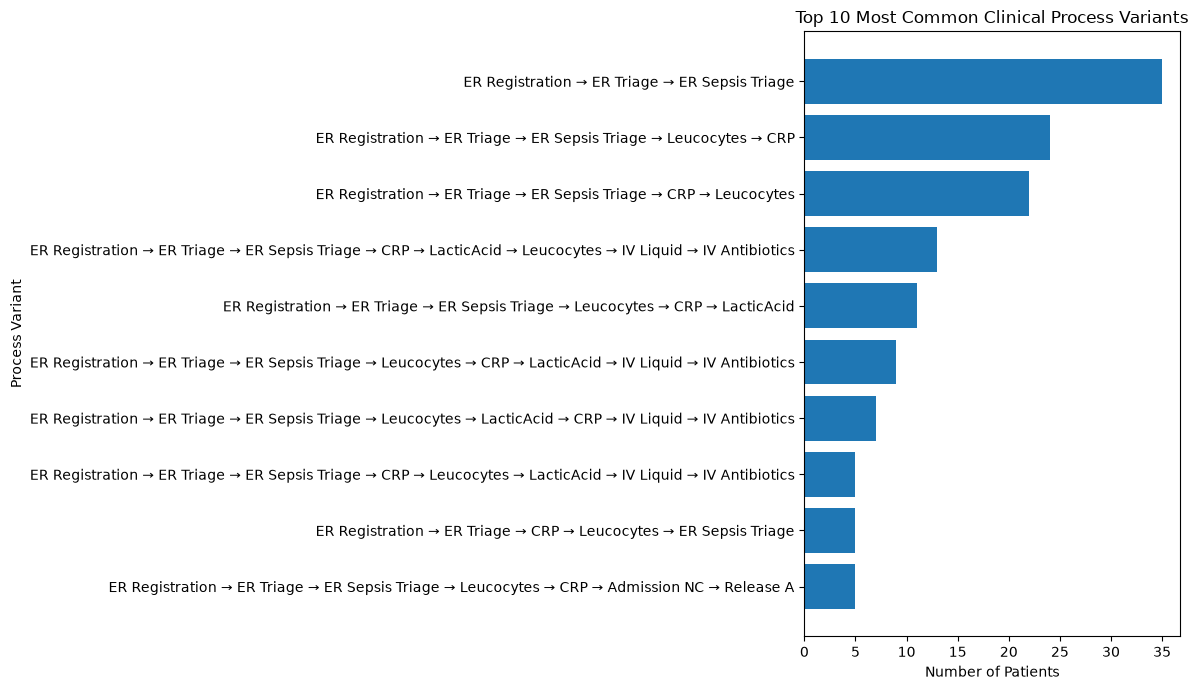

In [44]:
# Top 10 most common process variants

top_variants = variant_table.head(10).copy()

plt.figure(figsize=(12, 7))

plt.barh(
    top_variants["Process Variant"].astype(str),
    top_variants["Case Count"]
)

plt.xlabel("Number of Patients")
plt.ylabel("Process Variant")
plt.title("Top 10 Most Common Clinical Process Variants")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

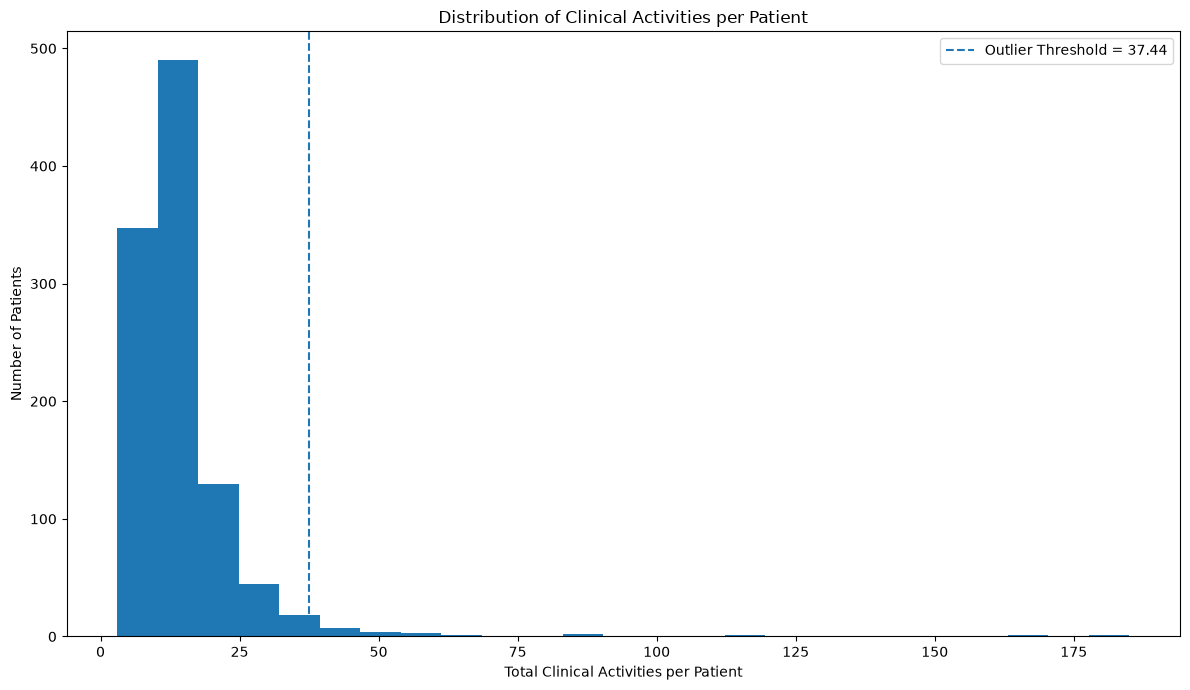

In [45]:
# Patient activity distribution

plt.figure(figsize=(12, 7))

plt.hist(
    patient_activity_summary["Total_Activities"],
    bins=25
)

plt.axvline(
    outlier_threshold,
    linestyle="--",
    label=f"Outlier Threshold = {outlier_threshold:.2f}"
)

plt.xlabel("Total Clinical Activities per Patient")
plt.ylabel("Number of Patients")
plt.title("Distribution of Clinical Activities per Patient")
plt.legend()

plt.tight_layout()
plt.show()

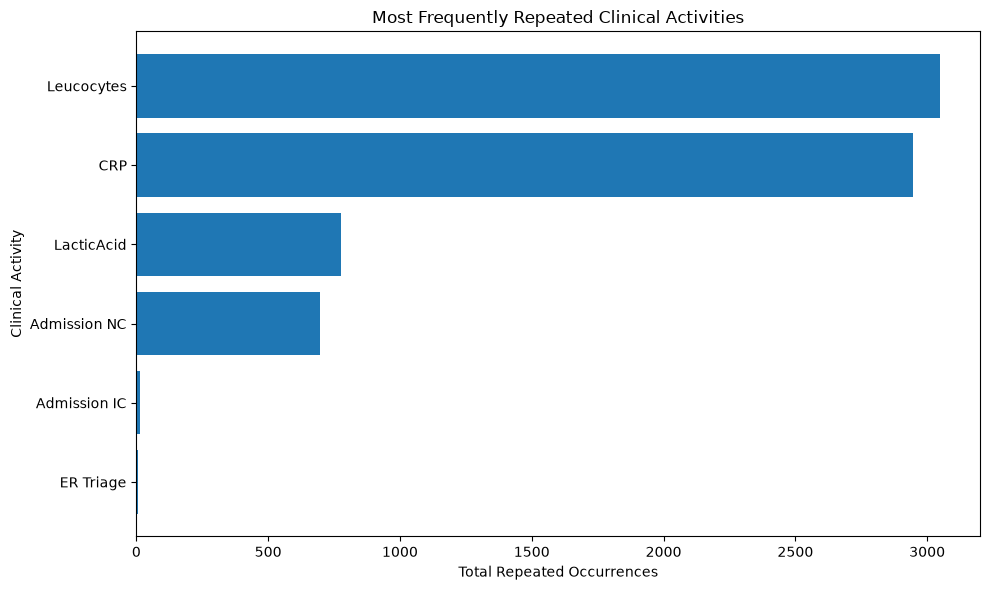

In [46]:
# Repeated clinical activities

plot_data = repeated_activity_summary.sort_values(
    "Total_Repeated_Occurrences",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["Total_Repeated_Occurrences"]
)

plt.xlabel("Total Repeated Occurrences")
plt.ylabel("Clinical Activity")
plt.title("Most Frequently Repeated Clinical Activities")

plt.tight_layout()
plt.show()

# CAREFLOW — Final Project Summary

## Project Objective

CareFlow analyzes healthcare event logs using process mining and data analytics techniques to understand patient pathways, clinical activity patterns, process variations, repeated activities, delays, and unusual patient journeys.

## Analysis Performed

1. Dataset loading and validation
2. Data quality and missing-value analysis
3. Clinical activity coverage analysis
4. Patient journey analysis
5. Process variant analysis
6. Directly-Follows Graph (DFG) discovery
7. Process map visualization
8. Rare and unusual pathway detection
9. Pathway complexity analysis
10. Repeated activity analysis
11. Patient-level outlier detection
12. Bottleneck and delay analysis
13. Clinical loop/rework analysis
14. Final process visualizations

## Major Findings

- 1,050 patient cases were analyzed.
- 15,214 clinical events were recorded.
- 16 distinct clinical activities were identified.
- 846 unique process variants were discovered.
- 819 process variants occurred in only 1–2 cases.
- 23 high-activity patient outliers were identified.
- Leucocytes and CRP were the most frequently repeated clinical activities.
- Repeated clinical monitoring loops were observed for Leucocytes, CRP, LacticAcid, and Admission NC.
- Several transitions showed substantial time intervals that require clinical interpretation.
- The overall process demonstrates high variability in patient journeys.

## Conclusion

The CareFlow analysis demonstrates how process mining can be used to understand complex healthcare workflows. The identified process variants, repeated activities, loops, delays, and outlier patient journeys provide useful evidence for further investigation of clinical workflow performance and potential process improvement opportunities.